# SHAP Explanations under Feature Correlation: How Faithful are they?

**Track 1 - Experimental investigation of an existing XAI approach**

Authors: N. Venkata Nivas Yadav (142301029), K. Sreekanth Naik (142301018)

This notebook runs the whole project from start to finish:

| Part | What it does |
|---|---|
| 0 | Setup: imports, settings, folders, library versions |
| 1 | Helper functions: make data, train model, SHAP, permutation importance, feature removal |
| 2 | Main synthetic experiment (x1, x2 correlated at 0.0 ... 0.99, 10 random seeds) |
| 3 | Summary tables (mean and standard deviation over seeds) |
| 4 | Figures for the synthetic experiment |
| 5 | Real-world check on the scikit-learn Diabetes dataset |
| 6 | Real-world "injected correlation" test (add a noisy copy of `bmi`) |
| 7 | Hypothesis verdicts (H1, H2, H3) printed from the numbers |

Everything is saved in `results/` (CSV tables) and `figures/` (PNG plots).
In Google Colab: upload this notebook, run `!pip install shap` once, then Runtime -> Run all.

In [2]:
%pip install shap

Defaulting to user installation because normal site-packages is not writeable
  Using cached slicer-0.0.8-py3-none-any.whl.metadata (4.0 kB)
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ------------- -------------------------- 262.1/751.9 kB ? eta -:--:--
   ------------- -------------------------- 262.1/751.9 kB ? eta -:--:--
   ------------- -------------------------- 262.1/751.9 kB ? eta -:--:--
   ------------- -------------------------- 262.1/751.9 kB ? eta -:--:--
   -------------------------- ----------- 524.3/751.9 kB 303.3 kB/s eta 0:00:01
   -------------------------- ----------- 524.3/751.9 kB 303.

In [3]:
# ===================================================================
# PART 0 - SETUP
# ===================================================================
import os
import json
import time
import platform
import warnings

import numpy as np
import pandas as pd
import sys
import matplotlib
IN_NOTEBOOK = "ipykernel" in sys.modules   # notebook: show plots on screen; script: only save
if not IN_NOTEBOOK:
    matplotlib.use("Agg")                  # draw plots to files (works without a screen)
import matplotlib.pyplot as plt
import scipy
from scipy.stats import spearmanr

import sklearn
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.datasets import load_diabetes

import shap

warnings.filterwarnings("ignore")

# ---------------- Experiment settings (change here, nothing else) ----------------
QUICK_MODE = False                      # True = tiny fast run, only for testing the code

CORRELATION_LEVELS = [0.0, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99]   # proposal used 0.0, 0.5, 0.9
PROPOSAL_LEVELS = [0.0, 0.5, 0.9]       # the three levels named in the proposal
SEEDS = list(range(10))                 # 10 repeated runs per correlation level
N_SAMPLES = 2000                        # rows in each synthetic dataset
TEST_SIZE = 0.30                        # 30 % of rows kept aside as the held-out test set
NOISE_STD = 1.0                         # standard deviation of the noise term epsilon
BETA = {"x1": 3.0, "x2": 2.0, "x3": 0.0, "x4": 0.0}   # true rule: y = 3*x1 + 2*x2 + eps
FEATURES = list(BETA.keys())

RF_PARAMS = dict(n_estimators=200, min_samples_leaf=5, n_jobs=-1)
N_EXPLAIN = 300        # number of test rows explained with SHAP
N_BACKGROUND = 100     # background rows for interventional SHAP
PI_REPEATS = 10        # how many times each feature is shuffled in permutation importance
REMOVAL_REPEATS = 5    # how many random shuffles are averaged in the removal test

if QUICK_MODE:
    CORRELATION_LEVELS, SEEDS = [0.0, 0.9], [0, 1]
    RF_PARAMS["n_estimators"], N_EXPLAIN, PI_REPEATS = 50, 100, 3

RESULTS_DIR, FIG_DIR = "results", "figures"
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

# Colours (colour-blind-checked palette). Each method/feature always keeps the same colour.
METHOD_COLORS = {"SHAP (tree-path)": "#2a78d6", "SHAP (interventional)": "#eb6834",
                 "Permutation importance": "#1baf7a", "Oracle (true rule)": "#52514e",
                 "Random ranking": "#e87ba4"}
METHOD_MARKERS = {"SHAP (tree-path)": "o", "SHAP (interventional)": "s",
                  "Permutation importance": "^", "Oracle (true rule)": "D", "Random ranking": "x"}
FEATURE_COLORS = {"x1": "#2a78d6", "x2": "#eb6834", "x3": "#1baf7a", "x4": "#eda100"}
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#c3c2b7", "axes.grid": True, "grid.color": "#e1e0d9",
                     "grid.linewidth": 0.6, "axes.facecolor": "#fcfcfb",
                     "figure.facecolor": "white", "legend.frameon": False})

# Log library versions (the proposal's "risk and mitigation" promise)
env = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
       "scipy": scipy.__version__, "scikit-learn": sklearn.__version__, "shap": shap.__version__,
       "matplotlib": matplotlib.__version__, "quick_mode": QUICK_MODE}
with open(os.path.join(RESULTS_DIR, "environment.json"), "w") as f:
    json.dump(env, f, indent=2)
print("Library versions:", env)


Library versions: {'python': '3.13.5', 'numpy': '2.1.3', 'pandas': '2.2.3', 'scipy': '1.15.3', 'scikit-learn': '1.6.1', 'shap': '0.54.1', 'matplotlib': '3.10.0', 'quick_mode': False}


## Part 1 - Helper functions
Each function does one job. They are reused by both the synthetic and the real-world experiments.

In [4]:
# ===================================================================
# PART 1 - HELPER FUNCTIONS
# ===================================================================

def make_synthetic_data(rho, n=N_SAMPLES, seed=0):
    """Create 4 features and a target with a KNOWN rule.
    x1, x2 : standard normal, correlation = rho (built exactly this way:
             x2 = rho*x1 + sqrt(1-rho^2)*z, so corr(x1, x2) = rho)
    x3, x4 : pure noise features, not used by the rule
    y      : 3*x1 + 2*x2 + eps
    """
    rng = np.random.default_rng(seed)
    x1 = rng.standard_normal(n)
    z = rng.standard_normal(n)
    x2 = rho * x1 + np.sqrt(1 - rho ** 2) * z
    x3 = rng.standard_normal(n)
    x4 = rng.standard_normal(n)
    X = pd.DataFrame({"x1": x1, "x2": x2, "x3": x3, "x4": x4})
    eps = rng.normal(0, NOISE_STD, n)
    y = BETA["x1"] * x1 + BETA["x2"] * x2 + eps
    return X, y


def true_reference_shares(rho):
    """What a PERFECT model would give for 'share of x1' = imp(x1) / (imp(x1) + imp(x2)).
    These are exact formulas for the true rule y = 3x1 + 2x2 (derivation in the report).
      interventional SHAP  : mean|phi1| ~ 3 , mean|phi2| ~ 2          -> 0.60 always
      conditional SHAP     : credit is shared as rho grows             -> 0.60 down to 0.50
      permutation (R2 drop): drop ~ 2*beta^2                           -> 9/13 = 0.69 always
    """
    a1, a2 = 3 + rho, -1.5 * rho          # phi1 = a1*x1 + a2*x2  (conditional Shapley value)
    b1, b2 = -rho, 2 + 1.5 * rho          # phi2 = b1*x1 + b2*x2
    sd1 = np.sqrt(a1 ** 2 + a2 ** 2 + 2 * a1 * a2 * rho)
    sd2 = np.sqrt(b1 ** 2 + b2 ** 2 + 2 * b1 * b2 * rho)
    return {"interventional_shap": 0.6, "conditional_shap": sd1 / (sd1 + sd2),
            "permutation": 9 / 13}


def train_model(X_train, y_train, seed):
    """Train the Random Forest regressor (Breiman, 2001)."""
    model = RandomForestRegressor(random_state=seed, **RF_PARAMS)
    model.fit(X_train, y_train)
    return model


def evaluate(model, X_test, y_test):
    """R2 (1 = perfect, 0 = no better than predicting the mean) and RMSE (average error size)."""
    pred = model.predict(X_test)
    return r2_score(y_test, pred), float(np.sqrt(mean_squared_error(y_test, pred)))


def shap_importance(model, X_explain, X_background=None):
    """Global SHAP importance = mean absolute SHAP value of each feature.
    X_background=None -> TreeExplainer default ('tree_path_dependent', follows the tree's own
                         training splits; behaves roughly like a conditional explanation)
    X_background=data -> 'interventional' (breaks the link between features; explains
                         the model function itself)
    Also returns the RELATIVE additivity error: mean |prediction - (base value + sum of SHAP)|
    divided by mean |prediction - base value|. 0.0 = SHAP adds up perfectly; 0.01 = 1 % gap.
    """
    if X_background is None:
        explainer = shap.TreeExplainer(model)
    else:
        explainer = shap.TreeExplainer(model, data=X_background,
                                       feature_perturbation="interventional")
    sv = np.asarray(explainer.shap_values(X_explain, check_additivity=False))
    assert sv.shape == X_explain.shape, f"unexpected SHAP output shape {sv.shape}"
    base = float(np.ravel(explainer.expected_value)[0])
    pred = model.predict(X_explain)
    gap = np.abs(pred - (base + sv.sum(axis=1)))
    # additivity error relative to the typical size of a prediction's deviation from the base value
    additivity_error = float(gap.mean() / (np.abs(pred - base).mean() + 1e-12))
    importance = pd.Series(np.abs(sv).mean(axis=0), index=X_explain.columns)
    return importance, additivity_error, sv


def permutation_imp(model, X_test, y_test, seed):
    """Baseline: drop in test R2 when one feature is shuffled (others kept)."""
    r = permutation_importance(model, X_test, y_test, n_repeats=PI_REPEATS,
                               random_state=seed, scoring="r2", n_jobs=1)
    return (pd.Series(r.importances_mean, index=X_test.columns),
            pd.Series(r.importances_std, index=X_test.columns))


def ranking(importance):
    """Feature names sorted from most to least important."""
    return list(importance.sort_values(ascending=False).index)


def removal_curve(ranked, model, X_train, y_train, X_test, y_test, seed, retrain_cache):
    """Feature-removal faithfulness test. Remove the top-k ranked features (k = 0..all) and
    record the test R2 in two ways:
      'permute' : keep the trained model, shuffle the removed columns in the test set
      'retrain' : train a NEW model without the removed columns (no unrealistic rows)
    A good ranking makes R2 fall fast. Retrained models are cached by feature set.
    """
    rng = np.random.default_rng(seed + 999)
    rows = []
    for k in range(len(ranked) + 1):
        removed = ranked[:k]
        # (a) permutation-based removal
        if k == 0:
            r2_perm = r2_score(y_test, model.predict(X_test))
        else:
            scores = []
            for _ in range(REMOVAL_REPEATS):
                Xp = X_test.copy()
                for col in removed:
                    Xp[col] = rng.permutation(Xp[col].values)
                scores.append(r2_score(y_test, model.predict(Xp)))
            r2_perm = float(np.mean(scores))
        # (b) retrain-based removal
        key = frozenset(removed)
        if key not in retrain_cache:
            kept = [c for c in X_train.columns if c not in removed]
            if kept:
                m = train_model(X_train[kept], y_train, seed)
                retrain_cache[key] = r2_score(y_test, m.predict(X_test[kept]))
            else:   # nothing left: best guess is the training mean
                retrain_cache[key] = r2_score(y_test, np.full(len(y_test), np.mean(y_train)))
        rows.append({"k_removed": k, "removed": ",".join(removed),
                     "r2_permute": r2_perm, "r2_retrain": retrain_cache[key]})
    return rows


def share_x1(imp, a="x1", b="x2"):
    """Share of the credit that goes to feature a when only a and b are compared.
    Negative permutation scores (pure chance) are treated as 0 so the share stays in [0, 1]."""
    va, vb = max(float(imp[a]), 0.0), max(float(imp[b]), 0.0)
    return va / (va + vb) if (va + vb) > 0 else np.nan


def safe_spearman(u, v):
    """Spearman rank correlation that returns NaN instead of crashing on constant input."""
    r = spearmanr(u, v).correlation
    return float(r) if np.isfinite(r) else np.nan


print("Helper functions ready.")


Helper functions ready.


## Part 2 - Main synthetic experiment
For every correlation level and every seed: make data -> split -> train -> evaluate ->
SHAP (two versions) -> permutation importance -> compare rankings -> feature-removal test.

In [5]:
# ===================================================================
# PART 2 - MAIN SYNTHETIC EXPERIMENT
# ===================================================================
run_rows, removal_rows, sample_store = [], [], {}
true_vec = np.array([BETA[f] for f in FEATURES])
t0 = time.time()

for rho in CORRELATION_LEVELS:
    for seed in SEEDS:
        # 1) data and fixed train/test split
        X, y = make_synthetic_data(rho, seed=seed)
        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE,
                                                            random_state=seed)
        # 2) model and predictive performance
        model = train_model(X_train, y_train, seed)
        r2, rmse = evaluate(model, X_test, y_test)
        # 3) explanations on the SAME model and SAME held-out rows
        X_explain = X_test.iloc[:N_EXPLAIN]
        X_bg = X_train.sample(N_BACKGROUND, random_state=seed)
        shap_path, err_path, sv_path = shap_importance(model, X_explain)
        shap_int, err_int, _ = shap_importance(model, X_explain, X_bg)
        pfi, pfi_std = permutation_imp(model, X_test, y_test, seed)
        methods = {"SHAP (tree-path)": shap_path, "SHAP (interventional)": shap_int,
                   "Permutation importance": pfi}

        row = {"rho_target": rho, "seed": seed,
               "rho_empirical": float(np.corrcoef(X["x1"], X["x2"])[0, 1]),
               "r2": r2, "rmse": rmse,
               "additivity_err_path": err_path, "additivity_err_int": err_int}
        for name, tag in [("SHAP (tree-path)", "shap_path"), ("SHAP (interventional)", "shap_int"),
                          ("Permutation importance", "pfi")]:
            imp = methods[name]
            for f in FEATURES:
                row[f"{tag}_{f}"] = float(imp[f])
            row[f"{tag}_share_x1"] = share_x1(imp)
            rk = ranking(imp)
            row[f"{tag}_rank"] = ">".join(rk)
            row[f"{tag}_x1_above_x2"] = int(rk.index("x1") < rk.index("x2"))
            row[f"{tag}_top2_correct"] = int(set(rk[:2]) == {"x1", "x2"})
            row[f"{tag}_spearman_truth"] = safe_spearman(imp[FEATURES].values, true_vec)
        for f in FEATURES:
            row[f"pfi_std_{f}"] = float(pfi_std[f])
        row["spearman_path_vs_pfi"] = safe_spearman(shap_path[FEATURES], pfi[FEATURES])
        row["spearman_int_vs_pfi"] = safe_spearman(shap_int[FEATURES], pfi[FEATURES])
        row["spearman_path_vs_int"] = safe_spearman(shap_path[FEATURES], shap_int[FEATURES])
        run_rows.append(row)

        # 4) feature-removal faithfulness test for each ranking (+ oracle and random baselines)
        rankings = {name: ranking(imp) for name, imp in methods.items()}
        rankings["Oracle (true rule)"] = ["x1", "x2", "x3", "x4"]
        rankings["Random ranking"] = list(np.random.default_rng(seed + 7).permutation(FEATURES))
        cache = {}
        for name, rk in rankings.items():
            for r in removal_curve(rk, model, X_train, y_train, X_test, y_test, seed, cache):
                removal_rows.append({"rho_target": rho, "seed": seed, "method": name, **r})

        if seed == SEEDS[0]:   # keep one example for the scatter / beeswarm figures
            sample_store[rho] = {"X": X, "sv_path": sv_path, "X_explain": X_explain}
    print(f"rho={rho:<5} done  ({time.time() - t0:5.1f} s so far)")

runs = pd.DataFrame(run_rows)
removal = pd.DataFrame(removal_rows)
runs.to_csv(os.path.join(RESULTS_DIR, "synthetic_runs_all_seeds.csv"), index=False)
removal.to_csv(os.path.join(RESULTS_DIR, "synthetic_feature_removal_all_seeds.csv"), index=False)
print(f"Finished {len(runs)} runs in {time.time() - t0:.1f} s")

rho=0.0   done  (172.7 s so far)
rho=0.25  done  (345.6 s so far)
rho=0.5   done  (524.6 s so far)
rho=0.75  done  (698.3 s so far)
rho=0.9   done  (869.6 s so far)
rho=0.95  done  (1042.8 s so far)
rho=0.99  done  (1219.7 s so far)
Finished 70 runs in 1219.8 s


rho=0.25  done  (309.3 s so far)


rho=0.5   done  (462.3 s so far)


rho=0.75  done  (616.8 s so far)


rho=0.9   done  (767.9 s so far)


rho=0.95  done  (917.8 s so far)


rho=0.99  done  (1072.2 s so far)
Finished 70 runs in 1072.2 s


## Part 3 - Summary tables (mean and standard deviation over the seeds)

In [6]:
# ===================================================================
# PART 3 - SUMMARY TABLES
# ===================================================================
def mean_sd(df, cols, by="rho_target", digits=3):
    """Table with 'mean ± sd' over seeds for each correlation level."""
    g = df.groupby(by)[cols]
    m, s = g.mean(), g.std()
    out = m.round(digits).astype(str) + " ± " + s.round(digits).astype(str)
    return out.reset_index()

perf_table = mean_sd(runs, ["rho_empirical", "r2", "rmse"])
perf_table.to_csv(os.path.join(RESULTS_DIR, "table1_performance.csv"), index=False)

imp_cols = [f"{t}_{f}" for t in ["shap_path", "shap_int", "pfi"] for f in FEATURES]
imp_table = mean_sd(runs, imp_cols)
imp_table.to_csv(os.path.join(RESULTS_DIR, "table2_importances.csv"), index=False)

ref = pd.DataFrame([{"rho_target": r, **true_reference_shares(r)} for r in CORRELATION_LEVELS])
share_table = runs.groupby("rho_target")[["shap_path_share_x1", "shap_int_share_x1",
                                          "pfi_share_x1"]].agg(["mean", "std"]).round(3)
share_table.columns = [f"{a}_{b}" for a, b in share_table.columns]
share_table = share_table.reset_index().merge(ref.round(3), on="rho_target")
share_table.to_csv(os.path.join(RESULTS_DIR, "table3_x1_share_vs_truth.csv"), index=False)

agree_cols = ["spearman_path_vs_pfi", "spearman_int_vs_pfi", "spearman_path_vs_int",
              "shap_path_spearman_truth", "shap_int_spearman_truth", "pfi_spearman_truth"]
agree_table = mean_sd(runs, agree_cols)
agree_table.to_csv(os.path.join(RESULTS_DIR, "table4_rank_agreement.csv"), index=False)

rank_table = runs.groupby("rho_target")[[
    "shap_path_x1_above_x2", "shap_int_x1_above_x2", "pfi_x1_above_x2",
    "shap_path_top2_correct", "shap_int_top2_correct", "pfi_top2_correct"]].mean().round(2).reset_index()
rank_table.to_csv(os.path.join(RESULTS_DIR, "table5_ranking_correctness.csv"), index=False)

rem_summary = (removal.groupby(["rho_target", "method", "k_removed"])[["r2_permute", "r2_retrain"]]
               .agg(["mean", "std"]).round(3))
rem_summary.columns = [f"{a}_{b}" for a, b in rem_summary.columns]
rem_summary = rem_summary.reset_index()
rem_summary.to_csv(os.path.join(RESULTS_DIR, "table6_feature_removal.csv"), index=False)

# Removal drop after removing the top-1 feature (one number per method / level)
base = removal[removal.k_removed == 0][["rho_target", "seed", "method", "r2_permute", "r2_retrain"]]
top1 = removal[removal.k_removed == 1][["rho_target", "seed", "method", "r2_permute", "r2_retrain"]]
drop1 = base.merge(top1, on=["rho_target", "seed", "method"], suffixes=("_full", "_top1"))
drop1["drop_permute"] = drop1["r2_permute_full"] - drop1["r2_permute_top1"]
drop1["drop_retrain"] = drop1["r2_retrain_full"] - drop1["r2_retrain_top1"]
drop1_table = drop1.groupby(["rho_target", "method"])[["drop_permute", "drop_retrain"]].mean().round(3).reset_index()
drop1_table.to_csv(os.path.join(RESULTS_DIR, "table7_top1_removal_drop.csv"), index=False)

check = runs[["additivity_err_path", "additivity_err_int"]].max()
print("Largest SHAP additivity error (should be ~0):", check.to_dict())
print("\nTable 1 - predictive performance\n", perf_table.to_string(index=False))
print("\nTable 3 - share of credit given to x1 vs the true reference\n", share_table.to_string(index=False))
print("\nTable 4 - rank agreement (Spearman)\n", agree_table.to_string(index=False))
print("\nTable 5 - fraction of seeds with a correct ranking\n", rank_table.to_string(index=False))
print("\nTable 7 - R2 drop after removing the top-1 feature\n", drop1_table.to_string(index=False))

Largest SHAP additivity error (should be ~0): {'additivity_err_path': 5.928195086014107e-15, 'additivity_err_int': 1.2380021214549628e-08}

Table 1 - predictive performance
  rho_target  rho_empirical            r2          rmse
       0.00 -0.003 ± 0.019 0.913 ± 0.009 1.101 ± 0.051
       0.25  0.245 ± 0.016 0.929 ± 0.007 1.096 ± 0.054
       0.50  0.494 ± 0.011 0.941 ± 0.007 1.091 ± 0.056
       0.75  0.746 ± 0.005 0.949 ± 0.005 1.085 ± 0.054
       0.90  0.898 ± 0.002 0.954 ± 0.004 1.074 ± 0.052
       0.95  0.949 ± 0.001 0.955 ± 0.004 1.075 ± 0.052
       0.99     0.99 ± 0.0 0.956 ± 0.004  1.07 ± 0.056

Table 3 - share of credit given to x1 vs the true reference
  rho_target  shap_path_share_x1_mean  shap_path_share_x1_std  shap_int_share_x1_mean  shap_int_share_x1_std  pfi_share_x1_mean  pfi_share_x1_std  interventional_shap  conditional_shap  permutation
       0.00                    0.605                   0.010                   0.604                  0.011              0.701 

## Part 4 - Figures for the synthetic experiment

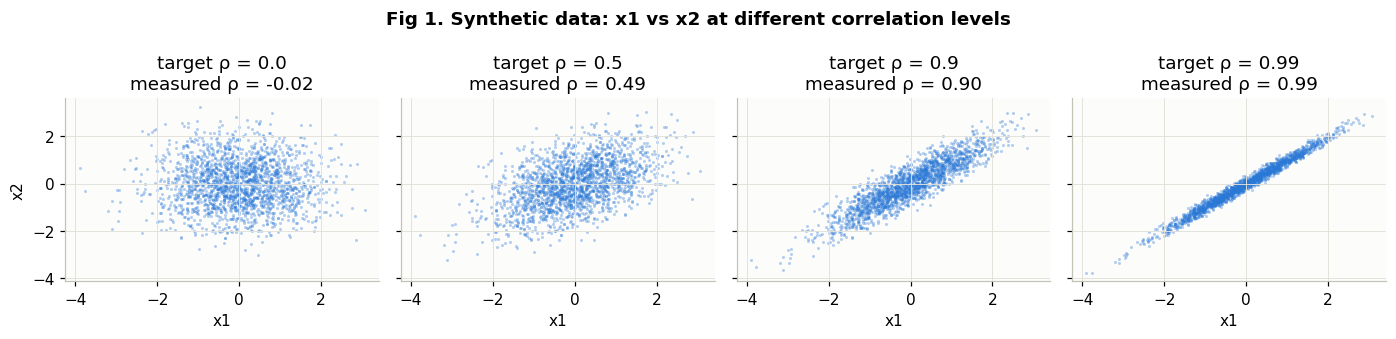

saved figures/fig1_correlation_check.png


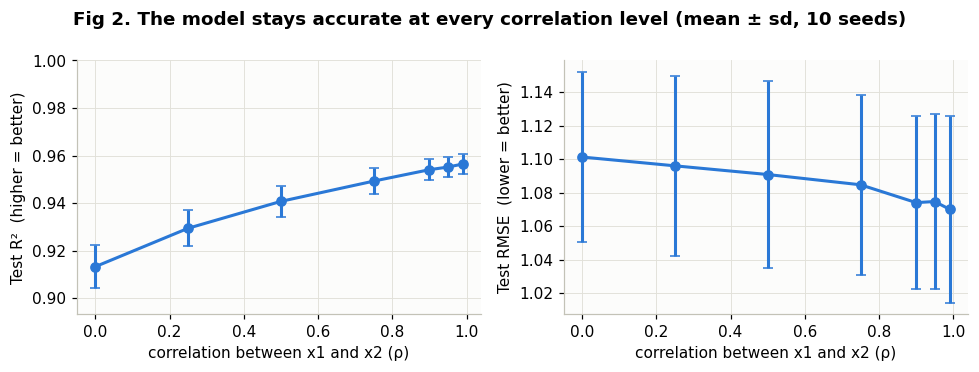

saved figures/fig2_performance_vs_correlation.png


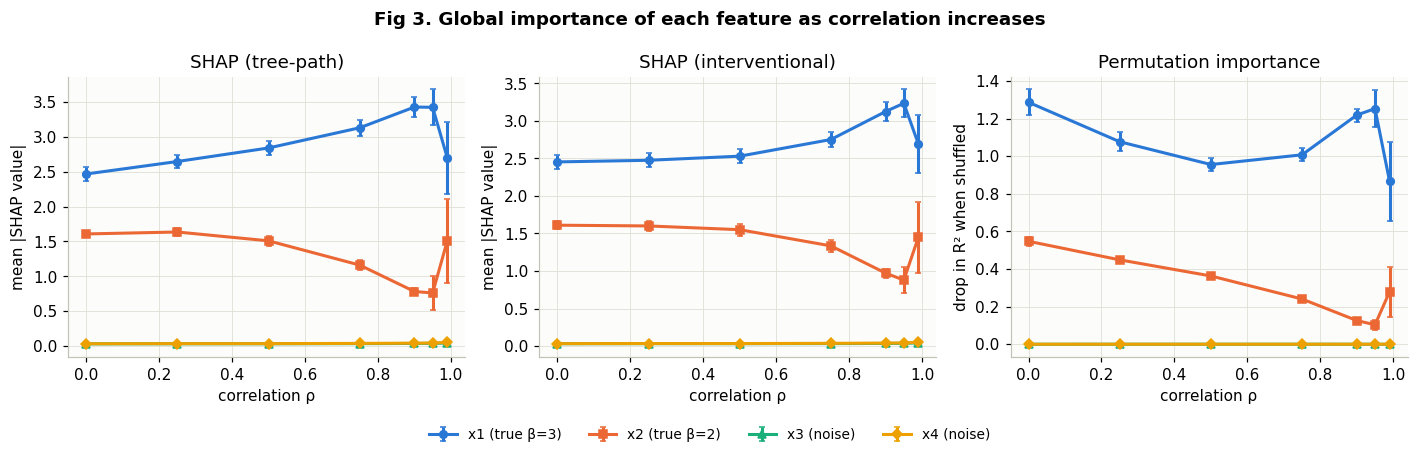

saved figures/fig3_importance_per_feature.png


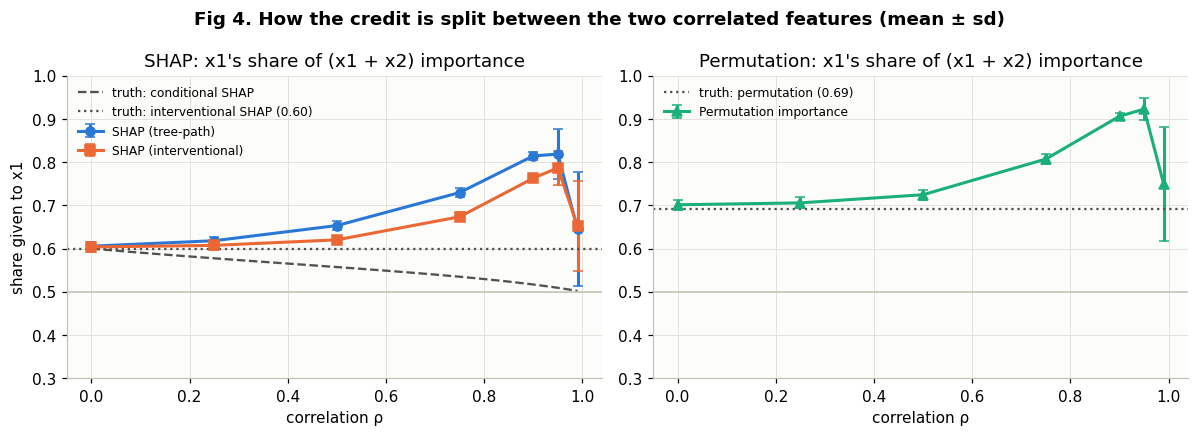

saved figures/fig4_x1_share_vs_truth.png


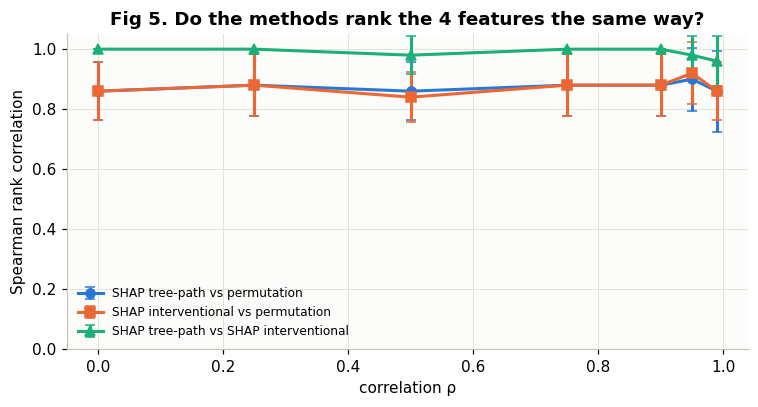

saved figures/fig5_rank_agreement.png


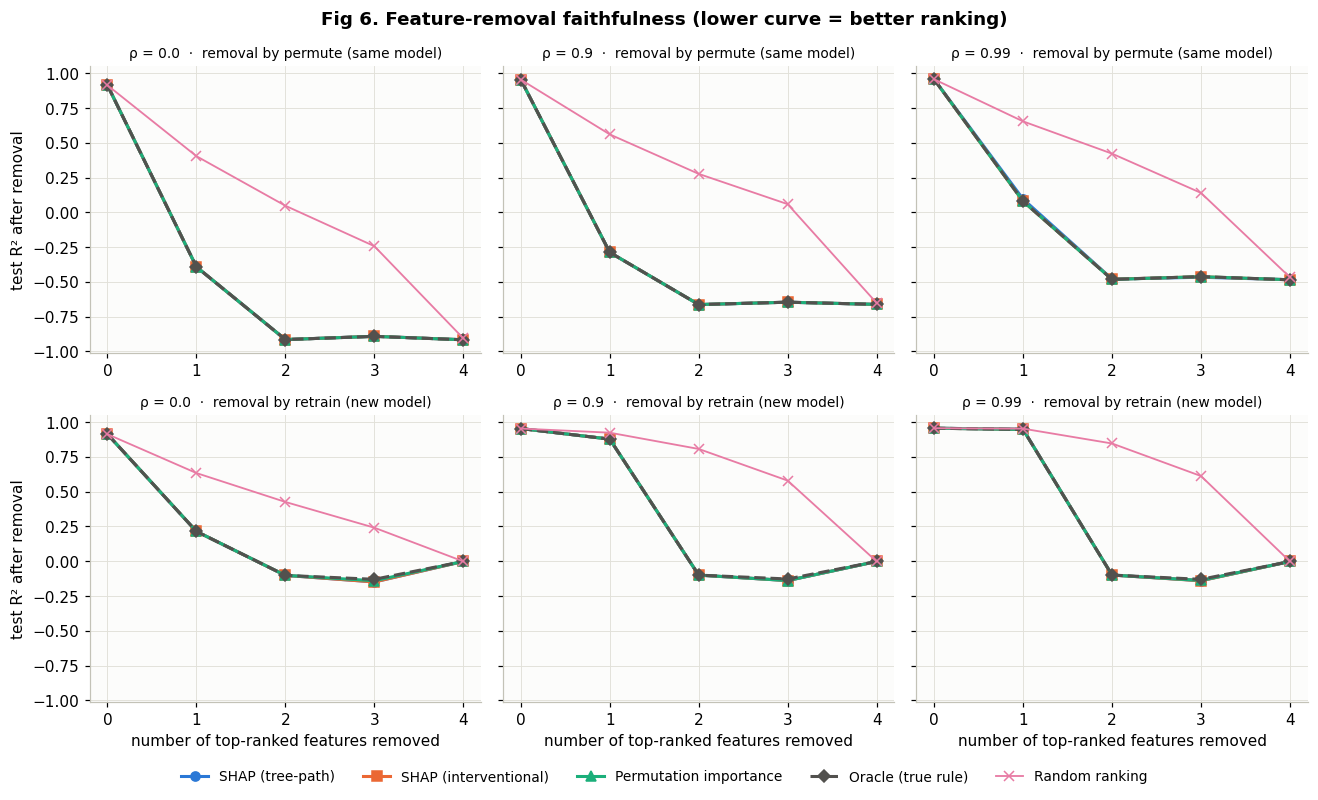

saved figures/fig6_feature_removal_curves.png


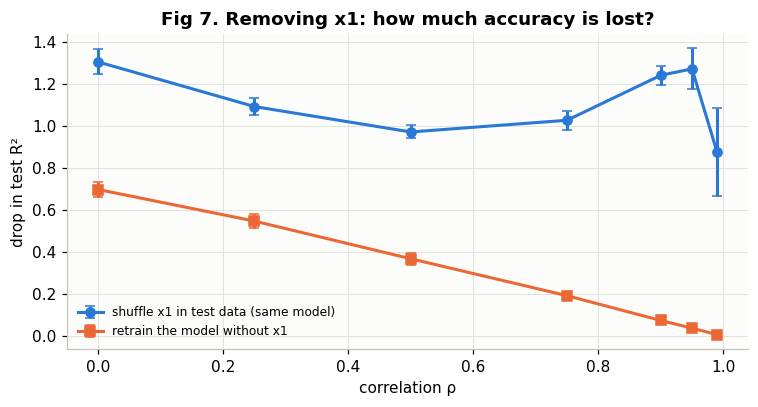

saved figures/fig7_remove_x1_permute_vs_retrain.png


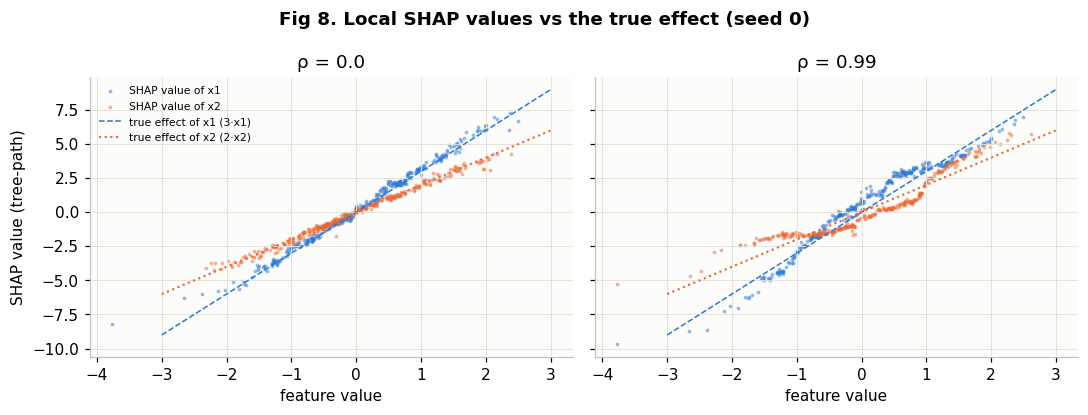

saved figures/fig8_local_shap_vs_truth.png


In [7]:
# ===================================================================
# PART 4 - FIGURES (synthetic)
# ===================================================================
def save(fig, name):
    fig.tight_layout()
    fig.savefig(os.path.join(FIG_DIR, name), bbox_inches="tight")
    if IN_NOTEBOOK:
        plt.show()
    plt.close(fig)
    print("saved figures/" + name)

g = runs.groupby("rho_target")
rhos = np.array(sorted(runs.rho_target.unique()))

# Fig 1 - did we really create the correlation we wanted?
show = [r for r in [0.0, 0.5, 0.9, 0.99] if r in sample_store]
fig, axes = plt.subplots(1, len(show), figsize=(3.2 * len(show), 3.1), sharex=True, sharey=True)
for ax, r in zip(np.atleast_1d(axes), show):
    Xs = sample_store[r]["X"]
    ax.scatter(Xs["x1"], Xs["x2"], s=4, alpha=0.35, color=FEATURE_COLORS["x1"], linewidths=0)
    ax.set_title(f"target ρ = {r}\nmeasured ρ = {np.corrcoef(Xs.x1, Xs.x2)[0, 1]:.2f}")
    ax.set_xlabel("x1")
np.atleast_1d(axes)[0].set_ylabel("x2")
fig.suptitle("Fig 1. Synthetic data: x1 vs x2 at different correlation levels", fontweight="bold")
save(fig, "fig1_correlation_check.png")

# Fig 2 - predictive performance vs correlation (H2)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
for ax, col, lab in [(axes[0], "r2", "Test R²  (higher = better)"),
                     (axes[1], "rmse", "Test RMSE  (lower = better)")]:
    ax.errorbar(rhos, g[col].mean(), yerr=g[col].std(), marker="o", color="#2a78d6",
                lw=2, capsize=3, ms=6)
    ax.set_xlabel("correlation between x1 and x2 (ρ)")
    ax.set_ylabel(lab)
axes[0].set_ylim(min(0.9, g["r2"].mean().min() - 0.02), 1.0)
fig.suptitle("Fig 2. The model stays accurate at every correlation level (mean ± sd, 10 seeds)",
             fontweight="bold")
save(fig, "fig2_performance_vs_correlation.png")

# Fig 3 - global importance of each feature vs correlation, one panel per method
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, (tag, title, unit) in zip(axes, [("shap_path", "SHAP (tree-path)", "mean |SHAP value|"),
                                          ("shap_int", "SHAP (interventional)", "mean |SHAP value|"),
                                          ("pfi", "Permutation importance", "drop in R² when shuffled")]):
    for f, mk in zip(FEATURES, ["o", "s", "^", "D"]):
        ax.errorbar(rhos, g[f"{tag}_{f}"].mean(), yerr=g[f"{tag}_{f}"].std(), marker=mk,
                    color=FEATURE_COLORS[f], lw=2, ms=5, capsize=2,
                    label=f + (" (true β=3)" if f == "x1" else " (true β=2)" if f == "x2" else " (noise)"))
    ax.set_title(title)
    ax.set_xlabel("correlation ρ")
    ax.set_ylabel(unit)
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=4, fontsize=9, bbox_to_anchor=(0.5, -0.08))
fig.suptitle("Fig 3. Global importance of each feature as correlation increases", fontweight="bold")
save(fig, "fig3_importance_per_feature.png")

# Fig 4 - share of credit for x1 vs the true reference (H1)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ax = axes[0]
for tag, name in [("shap_path", "SHAP (tree-path)"), ("shap_int", "SHAP (interventional)")]:
    ax.errorbar(rhos, g[f"{tag}_share_x1"].mean(), yerr=g[f"{tag}_share_x1"].std(), lw=2, ms=6,
                capsize=3, color=METHOD_COLORS[name], marker=METHOD_MARKERS[name], label=name)
ref_rhos = np.linspace(0, 0.99, 100)
ax.plot(ref_rhos, [true_reference_shares(r)["conditional_shap"] for r in ref_rhos], "--",
        color="#52514e", lw=1.5, label="truth: conditional SHAP")
ax.axhline(0.6, color="#52514e", ls=":", lw=1.5, label="truth: interventional SHAP (0.60)")
ax.axhline(0.5, color="#c3c2b7", lw=1)
ax.set_title("SHAP: x1's share of (x1 + x2) importance")
ax.set_xlabel("correlation ρ"); ax.set_ylabel("share given to x1"); ax.set_ylim(0.3, 1.0)
ax.legend(fontsize=8, loc="upper left")
ax = axes[1]
name = "Permutation importance"
ax.errorbar(rhos, g["pfi_share_x1"].mean(), yerr=g["pfi_share_x1"].std(), lw=2, ms=6, capsize=3,
            color=METHOD_COLORS[name], marker=METHOD_MARKERS[name], label=name)
ax.axhline(9 / 13, color="#52514e", ls=":", lw=1.5, label="truth: permutation (0.69)")
ax.axhline(0.5, color="#c3c2b7", lw=1)
ax.set_title("Permutation: x1's share of (x1 + x2) importance")
ax.set_xlabel("correlation ρ"); ax.set_ylim(0.3, 1.0)
ax.legend(fontsize=8, loc="upper left")
fig.suptitle("Fig 4. How the credit is split between the two correlated features (mean ± sd)",
             fontweight="bold")
save(fig, "fig4_x1_share_vs_truth.png")

# Fig 5 - ranking agreement (Spearman) vs correlation
fig, ax = plt.subplots(figsize=(7, 3.8))
for col, lab, c, mk in [("spearman_path_vs_pfi", "SHAP tree-path vs permutation", "#2a78d6", "o"),
                        ("spearman_int_vs_pfi", "SHAP interventional vs permutation", "#eb6834", "s"),
                        ("spearman_path_vs_int", "SHAP tree-path vs SHAP interventional", "#1baf7a", "^")]:
    ax.errorbar(rhos, g[col].mean(), yerr=g[col].std(), marker=mk, color=c, lw=2, capsize=3,
                ms=6, label=lab)
ax.set_ylim(0, 1.05); ax.set_xlabel("correlation ρ"); ax.set_ylabel("Spearman rank correlation")
ax.legend(fontsize=8, loc="lower left")
ax.set_title("Fig 5. Do the methods rank the 4 features the same way?", fontweight="bold")
save(fig, "fig5_rank_agreement.png")

# Fig 6 - feature-removal curves at three correlation levels (H3)
show = [r for r in [0.0, 0.9, 0.99] if r in rhos]
fig, axes = plt.subplots(2, len(show), figsize=(4 * len(show), 7), sharey=True)
axes = np.atleast_2d(axes)
for j, r in enumerate(show):
    sub = removal[removal.rho_target == r].groupby(["method", "k_removed"])[["r2_permute", "r2_retrain"]].mean().reset_index()
    for i, (col, lab) in enumerate([("r2_permute", "permute (same model)"),
                                    ("r2_retrain", "retrain (new model)")]):
        ax = axes[i, j]
        for name in METHOD_COLORS:
            s = sub[sub.method == name]
            ax.plot(s.k_removed, s[col], marker=METHOD_MARKERS[name], color=METHOD_COLORS[name],
                    lw=2 if "Random" not in name else 1.2, ms=6, label=name,
                    ls="-" if "Oracle" not in name else "--")
        ax.set_title(f"ρ = {r}  ·  removal by {lab}", fontsize=9)
        ax.set_xticks(range(5))
        if i == 1: ax.set_xlabel("number of top-ranked features removed")
        if j == 0: ax.set_ylabel("test R² after removal")
h, l = axes[0, 0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=5, fontsize=9, bbox_to_anchor=(0.5, -0.04))
fig.suptitle("Fig 6. Feature-removal faithfulness (lower curve = better ranking)", fontweight="bold")
save(fig, "fig6_feature_removal_curves.png")

# Fig 7 - what happens when x1 alone is removed, permute vs retrain
d = drop1[drop1.method == "Oracle (true rule)"].groupby("rho_target")[["drop_permute", "drop_retrain"]]
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.errorbar(rhos, d.mean()["drop_permute"], yerr=d.std()["drop_permute"], marker="o",
            color="#2a78d6", lw=2, capsize=3, label="shuffle x1 in test data (same model)")
ax.errorbar(rhos, d.mean()["drop_retrain"], yerr=d.std()["drop_retrain"], marker="s",
            color="#eb6834", lw=2, capsize=3, label="retrain the model without x1")
ax.set_xlabel("correlation ρ"); ax.set_ylabel("drop in test R²")
ax.legend(fontsize=8)
ax.set_title("Fig 7. Removing x1: how much accuracy is lost?", fontweight="bold")
save(fig, "fig7_remove_x1_permute_vs_retrain.png")

# Fig 8 - per-row SHAP values of x1 and x2 at rho = 0 and rho = 0.99 (local view)
show = [r for r in [0.0, 0.99] if r in sample_store]
fig, axes = plt.subplots(1, len(show), figsize=(5 * len(show), 3.8), sharey=True)
for ax, r in zip(np.atleast_1d(axes), show):
    st = sample_store[r]
    for k, f in enumerate(["x1", "x2"]):
        ax.scatter(st["X_explain"][f], st["sv_path"][:, k], s=6, alpha=0.5,
                   color=FEATURE_COLORS[f], label=f"SHAP value of {f}", linewidths=0)
    xs = np.linspace(-3, 3, 10)
    ax.plot(xs, 3 * xs, "--", color="#2a78d6", lw=1, label="true effect of x1 (3·x1)")
    ax.plot(xs, 2 * xs, ":", color="#eb6834", lw=1.4, label="true effect of x2 (2·x2)")
    ax.set_title(f"ρ = {r}"); ax.set_xlabel("feature value")
np.atleast_1d(axes)[0].set_ylabel("SHAP value (tree-path)")
np.atleast_1d(axes)[0].legend(fontsize=7)
fig.suptitle("Fig 8. Local SHAP values vs the true effect (seed 0)", fontweight="bold")
save(fig, "fig8_local_shap_vs_truth.png")

## Part 5 - Real-world check: scikit-learn Diabetes dataset
442 patients, 10 features, target = disease progression after one year.
It is bundled inside scikit-learn (no download needed) and it naturally contains strongly
correlated features (`s1` total cholesterol and `s2` LDL cholesterol, ρ ≈ 0.90).

In [ ]:
# ===================================================================
# PART 5 - REAL-WORLD DATASET
# ===================================================================
data = load_diabetes(as_frame=True)
Xd, yd = data.data, data.target.values
RF_FEATS = list(Xd.columns)

corr = Xd.corr()
corr.round(2).to_csv(os.path.join(RESULTS_DIR, "real_feature_correlations.csv"))
pairs = (corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack()
         .rename("rho").reset_index().assign(abs_rho=lambda d: d.rho.abs())
         .sort_values("abs_rho", ascending=False))
print("Most correlated feature pairs in the Diabetes data:\n", pairs.head(5).round(2).to_string(index=False))

real_rows, real_removal = [], []
for seed in SEEDS:
    Xtr, Xte, ytr, yte = train_test_split(Xd, yd, test_size=TEST_SIZE, random_state=seed)
    m = train_model(Xtr, ytr, seed)
    r2, rmse = evaluate(m, Xte, yte)
    sp, e1, _ = shap_importance(m, Xte)
    si, e2, _ = shap_importance(m, Xte, Xtr.sample(min(N_BACKGROUND, len(Xtr)), random_state=seed))
    pf, _ = permutation_imp(m, Xte, yte, seed)
    row = {"seed": seed, "r2": r2, "rmse": rmse, "add_err_path": e1, "add_err_int": e2,
           "spearman_path_vs_pfi": safe_spearman(sp, pf), "spearman_int_vs_pfi": safe_spearman(si, pf),
           "spearman_path_vs_int": safe_spearman(sp, si),
           "top3_overlap_path_pfi": len(set(ranking(sp)[:3]) & set(ranking(pf)[:3])),
           "s1_share_path": share_x1(sp, "s1", "s2"), "s1_share_pfi": share_x1(pf, "s1", "s2")}
    for f in RF_FEATS:
        row[f"shap_path_{f}"], row[f"shap_int_{f}"], row[f"pfi_{f}"] = sp[f], si[f], pf[f]
    real_rows.append(row)
    ranks = {"SHAP (tree-path)": ranking(sp), "SHAP (interventional)": ranking(si),
             "Permutation importance": ranking(pf),
             "Random ranking": list(np.random.default_rng(seed + 7).permutation(RF_FEATS))}
    cache = {}
    for name, rk in ranks.items():
        for r in removal_curve(rk, m, Xtr, ytr, Xte, yte, seed, cache):
            real_removal.append({"seed": seed, "method": name, **r})

real = pd.DataFrame(real_rows)
real_rem = pd.DataFrame(real_removal)
real.to_csv(os.path.join(RESULTS_DIR, "real_runs_all_seeds.csv"), index=False)
real_rem.to_csv(os.path.join(RESULTS_DIR, "real_feature_removal_all_seeds.csv"), index=False)

real_imp = pd.DataFrame({
    "feature": RF_FEATS,
    "shap_path_mean": [real[f"shap_path_{f}"].mean() for f in RF_FEATS],
    "shap_int_mean": [real[f"shap_int_{f}"].mean() for f in RF_FEATS],
    "pfi_mean": [real[f"pfi_{f}"].mean() for f in RF_FEATS],
    "pfi_sd": [real[f"pfi_{f}"].std() for f in RF_FEATS]}).sort_values("shap_path_mean", ascending=False)
real_imp.round(4).to_csv(os.path.join(RESULTS_DIR, "real_table_importances.csv"), index=False)
real_summary = real.drop(columns=[c for c in real.columns if c.startswith(("shap_", "pfi_"))] + ["seed"]) \
                   .agg(["mean", "std"]).T.round(3)
real_summary.to_csv(os.path.join(RESULTS_DIR, "real_table_summary.csv"))
print("\nReal data summary (mean, sd over seeds)\n", real_summary.to_string())
print("\nReal data importances\n", real_imp.round(3).to_string(index=False))
for col, lab in [("add_err_path", "tree-path"), ("add_err_int", "interventional")]:
    worst = real[col].max()
    status = "OK" if worst < 0.01 else "FAILED - treat these SHAP values as approximate (see report)"
    print(f"Additivity check, {lab} SHAP on real data: worst relative gap = {worst:.4f} -> {status}")

# Fig 9 - correlation heatmap of the real features
fig, ax = plt.subplots(figsize=(6.2, 5.2))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(RF_FEATS))); ax.set_xticklabels(RF_FEATS, rotation=45)
ax.set_yticks(range(len(RF_FEATS))); ax.set_yticklabels(RF_FEATS)
ax.grid(False)
for i in range(len(RF_FEATS)):
    for j in range(len(RF_FEATS)):
        v = corr.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(v) > 0.6 else "#0b0b0b")
fig.colorbar(im, ax=ax, fraction=0.046, label="Pearson correlation")
ax.set_title("Fig 9. Diabetes data: correlation between features", fontweight="bold")
save(fig, "fig9_real_correlation_heatmap.png")

# Fig 10 - importances on real data (each method scaled so its largest value = 1)
fig, ax = plt.subplots(figsize=(9, 4))
order = real_imp.feature.tolist()
w = 0.27
for k, (col, name) in enumerate([("shap_path_mean", "SHAP (tree-path)"),
                                 ("shap_int_mean", "SHAP (interventional)"),
                                 ("pfi_mean", "Permutation importance")]):
    vals = real_imp.set_index("feature").loc[order, col]
    ax.bar(np.arange(len(order)) + (k - 1) * w, vals / vals.max(), width=w - 0.03,
           color=METHOD_COLORS[name], label=name)
ax.set_xticks(range(len(order))); ax.set_xticklabels(order)
ax.set_ylabel("importance (scaled, max = 1)")
ax.legend(fontsize=8)
ax.set_title("Fig 10. Diabetes data: global importance by method (mean of 10 seeds)", fontweight="bold")
save(fig, "fig10_real_importances.png")

# Fig 11 - removal curves on real data
sub = real_rem.groupby(["method", "k_removed"])[["r2_permute", "r2_retrain"]].mean().reset_index()
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, (col, lab) in zip(axes, [("r2_permute", "permute (same model)"), ("r2_retrain", "retrain (new model)")]):
    for name in ["SHAP (tree-path)", "SHAP (interventional)", "Permutation importance", "Random ranking"]:
        s = sub[sub.method == name]
        ax.plot(s.k_removed, s[col], marker=METHOD_MARKERS[name], color=METHOD_COLORS[name],
                lw=2, ms=5, label=name)
    ax.set_title(f"removal by {lab}", fontsize=9); ax.set_xlabel("number of top-ranked features removed")
axes[0].set_ylabel("test R² after removal"); axes[0].legend(fontsize=8)
fig.suptitle("Fig 11. Diabetes data: feature-removal faithfulness", fontweight="bold")
save(fig, "fig11_real_feature_removal.png")

Most correlated feature pairs in the Diabetes data:
 level_0 level_1   rho  abs_rho
     s1      s2  0.90     0.90
     s3      s4 -0.74     0.74
     s2      s4  0.66     0.66
     s4      s5  0.62     0.62
     s1      s4  0.54     0.54


saved figures/fig11_real_feature_removal.png


## Part 6 - Real-world "injected correlation" test
We add a new column `bmi_copy` that is a noisy copy of `bmi` with a chosen correlation.
The copy carries **no new information** - the real target never used it.
Question: how much of `bmi`'s credit does each method move to the copy?

In [ ]:
# ===================================================================
# PART 6 - INJECTED CORRELATION ON REAL DATA
# ===================================================================
INJECT_LEVELS = [0.0, 0.5, 0.9, 0.99]
inj_rows = []
for rho in INJECT_LEVELS:
    for seed in SEEDS:
        rng = np.random.default_rng(seed)
        b = (Xd["bmi"] - Xd["bmi"].mean()) / Xd["bmi"].std()
        copy = rho * b + np.sqrt(1 - rho ** 2) * rng.standard_normal(len(b))
        Xc = Xd.copy()
        Xc["bmi_copy"] = copy * Xd["bmi"].std() + Xd["bmi"].mean()
        Xtr, Xte, ytr, yte = train_test_split(Xc, yd, test_size=TEST_SIZE, random_state=seed)
        m = train_model(Xtr, ytr, seed)
        r2, _ = evaluate(m, Xte, yte)
        sp, _, _ = shap_importance(m, Xte)
        si, _, _ = shap_importance(m, Xte, Xtr.sample(N_BACKGROUND, random_state=seed))
        pf, _ = permutation_imp(m, Xte, yte, seed)
        inj_rows.append({"rho": rho, "seed": seed, "r2": r2,
                         "rho_empirical": float(np.corrcoef(Xc.bmi, Xc.bmi_copy)[0, 1]),
                         "bmi_share_shap_path": share_x1(sp, "bmi", "bmi_copy"),
                         "bmi_share_shap_int": share_x1(si, "bmi", "bmi_copy"),
                         "bmi_share_pfi": share_x1(pf, "bmi", "bmi_copy"),
                         "bmi_rank_shap_path": ranking(sp).index("bmi") + 1,
                         "bmi_rank_pfi": ranking(pf).index("bmi") + 1})
inj = pd.DataFrame(inj_rows)
inj.to_csv(os.path.join(RESULTS_DIR, "real_injected_all_seeds.csv"), index=False)
inj_table = inj.groupby("rho").agg(["mean", "std"]).drop(columns="seed").round(3)
inj_table.columns = [f"{a}_{b}" for a, b in inj_table.columns]
inj_table.reset_index().to_csv(os.path.join(RESULTS_DIR, "real_table_injected.csv"), index=False)
print(inj_table.to_string())

gi = inj.groupby("rho")
fig, ax = plt.subplots(figsize=(7, 3.8))
for col, name in [("bmi_share_shap_path", "SHAP (tree-path)"),
                  ("bmi_share_shap_int", "SHAP (interventional)"),
                  ("bmi_share_pfi", "Permutation importance")]:
    ax.errorbar(INJECT_LEVELS, gi[col].mean(), yerr=gi[col].std(), marker=METHOD_MARKERS[name],
                color=METHOD_COLORS[name], lw=2, capsize=3, ms=6, label=name)
ax.axhline(1.0, color="#52514e", ls=":", lw=1.5, label="ideal: all credit to real bmi")
ax.axhline(0.5, color="#c3c2b7", lw=1)
ax.set_ylim(0.0, 1.1); ax.set_xlabel("correlation between bmi and its fake copy")
ax.set_ylabel("share of credit kept by real bmi"); ax.legend(fontsize=8, loc="lower left")
ax.set_title("Fig 12. A fake copy of bmi steals credit as correlation grows", fontweight="bold")
save(fig, "fig12_real_injected_copy.png")

## Part 7 - Hypothesis verdicts
The verdicts below are computed from the numbers, not written by hand.

In [ ]:
# ===================================================================
# PART 7 - HYPOTHESIS VERDICTS
# ===================================================================
lo, hi = min(CORRELATION_LEVELS), max(CORRELATION_LEVELS)
gm = runs.groupby("rho_target").mean(numeric_only=True)
lines = []
lines.append("H1 (SHAP redistributes credit, rankings less consistent with the true rule):")
lines.append(f"  x1 share, SHAP tree-path:      {gm.shap_path_share_x1[lo]:.3f} (ρ={lo}) -> {gm.shap_path_share_x1[hi]:.3f} (ρ={hi}); "
             f"truth (interventional) 0.600")
lines.append(f"  x1 share, SHAP interventional: {gm.shap_int_share_x1[lo]:.3f} -> {gm.shap_int_share_x1[hi]:.3f}")
lines.append(f"  x1 share, permutation:         {gm.pfi_share_x1[lo]:.3f} -> {gm.pfi_share_x1[hi]:.3f}; truth 0.692")
lines.append(f"  seeds with x1 ranked above x2 (tree-path SHAP): {gm.shap_path_x1_above_x2[lo]:.0%} -> {gm.shap_path_x1_above_x2[hi]:.0%}")
lines.append(f"  seeds with x1 ranked above x2 (permutation):    {gm.pfi_x1_above_x2[lo]:.0%} -> {gm.pfi_x1_above_x2[hi]:.0%}")
lines.append("H2 (accuracy stays high while attributions change):")
lines.append(f"  test R2: {gm.r2[lo]:.3f} (ρ={lo}) -> {gm.r2[hi]:.3f} (ρ={hi})")
d1 = drop1[drop1.method == "Oracle (true rule)"].groupby("rho_target").mean(numeric_only=True)
lines.append("H3 (removal faithfulness changes with correlation):")
lines.append(f"  R2 lost when x1 is shuffled (same model): {d1.drop_permute[lo]:.3f} -> {d1.drop_permute[hi]:.3f}")
lines.append(f"  R2 lost when the model is retrained without x1: {d1.drop_retrain[lo]:.3f} -> {d1.drop_retrain[hi]:.3f}")
lines.append(f"  Spearman SHAP(tree-path) vs permutation: {gm.spearman_path_vs_pfi[lo]:.2f} -> {gm.spearman_path_vs_pfi[hi]:.2f}")
text = "\n".join(lines)
print(text)
with open(os.path.join(RESULTS_DIR, "hypothesis_verdicts.txt"), "w") as f:
    f.write(text + "\n")
print("\nAll done. Tables are in results/, plots are in figures/.")


All done. Tables are in results/, plots are in figures/.
